# **1. Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn import metrics

sns.set_theme(style="whitegrid")

# **2. Data Loading**

In [2]:
#data = pd.read_csv('/content/drive/MyDrive/DTS/Data Mining/Data/simulated_polynomial_data_curved.csv')
data = pd.read_csv('https://raw.githubusercontent.com/data-insight-hub92/data-mining/refs/heads/main/datasets/simulated_polynomial_data_curved.csv')
data.head()

,X,y
0,-10.000000,72.873036
1,-9.591837,61.554152
2,-9.183673,57.360924
3,-8.775510,51.449149
4,-8.367347,53.153491


# **3. Data Inspection**

In [3]:
# Ukuran dataset: jumlah baris dan kolom
print("Dataset shape:", data.shape)

# Informasi tipe data dan jumlah nilai non-null
data.info()

Dataset shape: (50, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       50 non-null     float64
 1   y       50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


In [4]:
# Statistik deskriptif untuk kolom numerik
data.describe().T

,count,mean,std,min,25%,50%,75%,max
X,50.0,1.421085e-16,5.949951,-10.000000,-5.000000,0.00000,5.000000,10.000000
y,50.0,2.027039e+01,18.473549,-0.817304,5.639231,13.78362,33.271603,72.873036


In [5]:
# Memeriksa missing values
data.isnull().sum()

,0
X,0
y,0


In [6]:
# Memeriksa jumlah baris duplikat
print("Jumlah baris duplikat:", data.duplicated().sum())

Jumlah baris duplikat: 0


# **4. Define Features and Target**

In [7]:
X = data[['X']]
y = data['y']

# **5. Train-Test Split**

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# **6. Exploratory Data Analysis (Training Data)**

**6.1 Distribusi Feature**

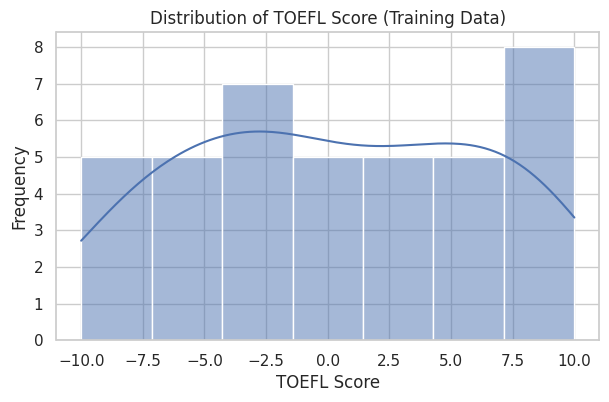

In [9]:
plt.figure(figsize=(7, 4))
sns.histplot(data=X_train, x='X', kde=True)
plt.title('Distribution of TOEFL Score (Training Data)')
plt.xlabel('TOEFL Score')
plt.ylabel('Frequency')
plt.show()

**6.2 Hubungan (Korelasi) Feature dan Target**

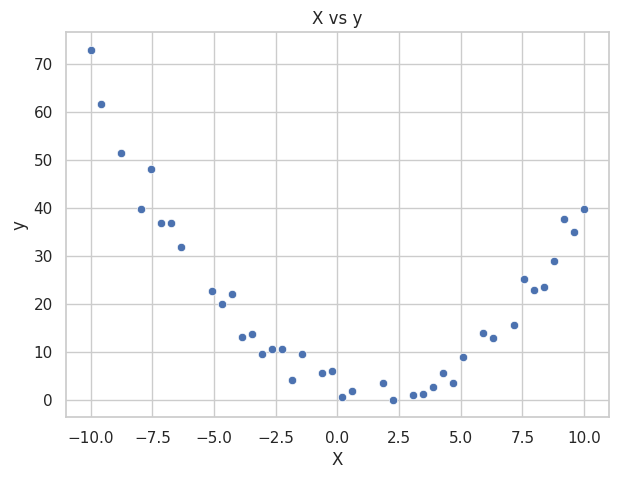

In [10]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_train['X'], y=y_train)
plt.title('X vs y')
plt.xlabel('X')
plt.ylabel('y')
plt.show()

In [11]:
data['X'].corr(y_train, method='spearman')

np.float64(-0.2660412757973734)

**6.3 Pemeriksaan Outlier pada Feature**

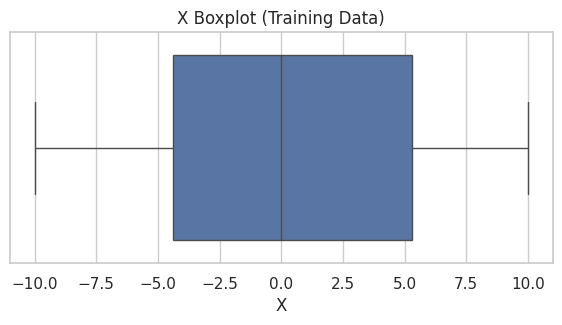

In [12]:
plt.figure(figsize=(7, 3))
sns.boxplot(x=X_train['X'])
plt.title('X Boxplot (Training Data)')
plt.xlabel('X')
plt.show()

# **7. Model Building**

In [13]:
# Buat fitur polinomial (derajat 2 atau sesuai kebutuhan)
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)

In [14]:
# Fit model regresi
model = LinearRegression()
model.fit(X_train_poly, y_train)

intercept = model.intercept_
coefficient = model.coef_

print("Intercept:", intercept)
print("Coefficient (TOEFL Score):", coefficient)

Intercept: 2.373324373966703
Coefficient (TOEFL Score): [ 0.         -1.43343765  0.51467707]


# **8. Prediction**

In [15]:
X_test_poly = poly.fit_transform(X_test)

In [16]:
y_pred = model.predict(X_test_poly)

prediction_results = pd.DataFrame({'Actual': y_test.to_numpy(), 'Predicted': y_pred})
prediction_results.head(10)

,Actual,Predicted
0,1.073887,1.375918
1,20.266059,25.898663
2,33.777411,28.884566
3,12.913123,16.063306
4,57.360924,58.945339
5,-0.817304,1.446532
6,14.895275,10.101595
7,1.349515,2.193001
8,7.756001,4.371915
9,53.153491,50.401220


# **9. Model Evaluation**

In [17]:
mae = metrics.mean_absolute_error(y_test, y_pred)
mse = metrics.mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100
r2 = metrics.r2_score(y_test, y_pred)

In [18]:
print('Mean Absolute Error: {:.4f}'.format(mae))
print('Mean Squared Error: {:.4f}'.format(mse))
print('Root Mean Squared Error: {:.4f}'.format(rmse))
print('R-Squared: {:.2f}%'.format(r2*100))
print('Mean Absolute Percentage Error (MAPE): {:.2f}%'.format(mape))

Mean Absolute Error: 2.9599
Mean Squared Error: 11.6034
Root Mean Squared Error: 3.4064
R-Squared: 97.14%
Mean Absolute Percentage Error (MAPE): 51.80%
